Dieses Notebook trägt die mathematischen und physikalischen Grundlagen zum Verständnis der Wellenfunktion zusammen. Los geht es mit dem Enheitskreis, um die mathematische Darstellung von Wellen zu erarbeiten.

# Kapitel 1: Trigonometrie

## 1.1 Der Einheitskreis

Ein Einheitskreis besitzt den Radius 1.

Ein Punkt auf dem Kreis hat die Koordinaten:

$$P(\varphi)=(\cos\varphi,\sin\varphi)$$

Dabei gilt:

$$\sin^2(\varphi)+\cos^2(\varphi)=1$$

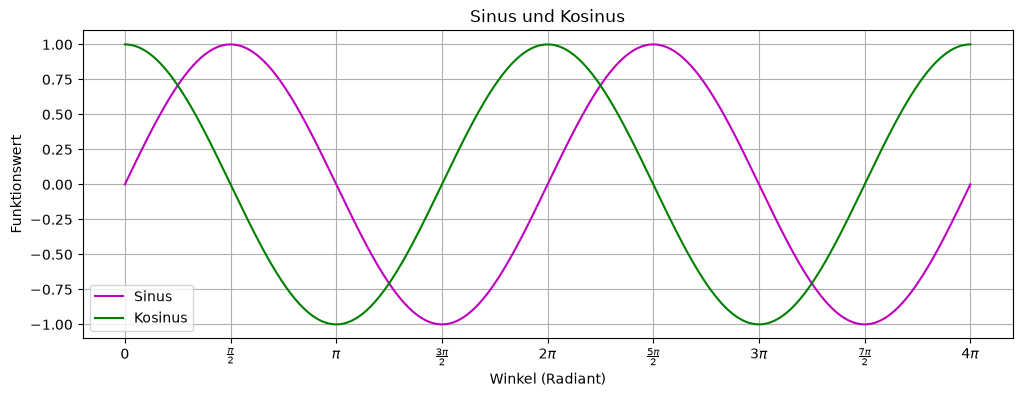

In [123]:

import numpy as np
import matplotlib.pyplot as plt

phi = np.linspace(0, 4*np.pi, 500)

sinus = np.sin(phi)
kosinus = np.cos(phi)

plt.figure(figsize=(12, 4))

plt.plot(phi, sinus, 'm-', label="Sinus")
plt.plot(phi, kosinus, 'g-', label="Kosinus")
plt.xticks(
    [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi,
     5*np.pi/2, 3*np.pi, 7*np.pi/2, 4*np.pi],
    ['0', r'$\frac{\pi}{2}$', r'$\pi$',
     r'$\frac{3\pi}{2}$', r'$2\pi$',
     r'$\frac{5\pi}{2}$', r'$3\pi$',
     r'$\frac{7\pi}{2}$', r'$4\pi$']
)

plt.xlabel("Winkel (Radiant)")
plt.ylabel("Funktionswert")
plt.title("Sinus und Kosinus")

plt.grid(True)
plt.legend()
plt.show()

In [124]:

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def zeichne(winkel):
    phi = np.deg2rad(winkel)

    x = np.cos(phi)
    y = np.sin(phi)

    t = np.linspace(0, 2*np.pi, 400)
    sin_cos_x = np.linspace(0, 4*np.pi, 500)
    sinus = np.sin(sin_cos_x)
    kosinus = np.cos(sin_cos_x)

    fig = plt.figure(figsize=(24, 6))
    gridspec = fig.add_gridspec(1, 2)

    ax = fig.add_subplot(gridspec[:, 0])
    ax_sin_cos = fig.add_subplot(gridspec[0, 1])

    # Einheitskreis
    ax.plot(np.cos(t), np.sin(t), 'b-')

    # Koordinatenachsen
    ax.axhline(0, color='gray')
    ax.axvline(0, color='gray')

    # Sinus und Kosinus
    ax.plot([0, x], [0, 0], 'g--', linewidth=3)
    ax.plot([x, x], [0, y], 'm:', linewidth=3)

    # Kreisbogen (rot/gelb)
    rad_bog = min(phi, 2 * np.pi)
    bog = np.linspace(rad_bog, 0, 400)
    ax.plot(np.cos(bog), np.sin(bog), 'r-', linewidth=3)
    dot_color = 'red'
    if winkel > 360:
        rad_sec = np.deg2rad(winkel - 360)
        bog_sec = np.linspace(rad_sec, 0, 400)
        ax.plot(np.cos(bog_sec), np.sin(bog_sec), '-', color='orange', linewidth=3)
        dot_color = 'orange'

    # Radius und Punkt
    ax.plot([0, x], [0, y], '-')
    ax.plot(x, y, 'o', color=dot_color, markersize=8)
    
    ax.set_aspect('equal')
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.grid(True)

    ax.set_title(f"Winkel = {winkel} Grad")

    # Sinus und Cosinus Plot
    ax_sin_cos.plot(sin_cos_x, sinus, 'm-', label="Sinus")
    ax_sin_cos.plot(sin_cos_x, kosinus, 'g-', label="Kosinus")
    ax_sin_cos.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi, 5*np.pi/2, 3*np.pi, 7*np.pi/2, 4*np.pi])
    ax_sin_cos.set_xticklabels(
    ['0', r'$\frac{\pi}{2}$', r'$\pi$', r'$\frac{3\pi}{2}$', r'$2\pi$', r'$\frac{5\pi}{2}$', r'$3\pi$', r'$\frac{7\pi}{2}$', r'$4\pi$']
)

    # Sinus, Kosinus, radiant
    ax_sin_cos.plot( [phi, phi], [x, 0], 'g--', linewidth=3)
    ax_sin_cos.plot(phi, x, 'go', markersize=8)
    ax_sin_cos.plot([phi, phi], [y, 0], 'm:', linewidth=3)
    ax_sin_cos.plot(phi, y, 'mo', markersize=8)

    
    ax_sin_cos.plot( [0, rad_bog], [0, 0], 'r-', linewidth=3)
    if winkel > 360:
        ax_sin_cos.plot( [rad_bog, phi], [0, 0], '-', color='orange', linewidth=3)
    ax_sin_cos.plot(phi, 0, 'o', color=dot_color, markersize=8)
    
    ax_sin_cos.set_xlim(-.3, 4*np.pi + .3)
    ax_sin_cos.set_ylim(-1.3, 1.3)
    ax_sin_cos.grid(True)
    ax_sin_cos.legend()

    ax_sin_cos.set_xlabel("Radiant")
    ax_sin_cos.set_ylabel("Funktionswert")
    ax_sin_cos.set_title("Sinus und Kosinus")

    plt.show()
    plt.close(fig)

    print(f"sin = {y:.5f}")
    print(f"cos = {x:.5f}")
    print(f"Radiant = {phi:.5f} rad")

regler = widgets.IntSlider(
    value=135,
    min=0,
    max=720,
    step=5,
    description="Winkel:"
)

ausgabe = widgets.interactive_output(
    zeichne,
    {"winkel": regler}
)

display(regler, ausgabe)

IntSlider(value=135, description='Winkel:', max=720, step=5)

Output()